# 9.3 Advanced Probability

**Goal:** model dependence across time with Markov chains, Poisson processes, martingales, and Brownian motion.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Information Theory](1_Information-Theory.ipynb)
2. [Statistical Learning Theory](2_Statistical-Learning-Theory.ipynb)
3. [Advanced Probability](3_Advanced-Probability.ipynb)
4. [Time-Series Statistics](4_Time-Series-Statistics.ipynb)
5. [Statistical Computing](5_Statistical-Computing.ipynb)
6. [Specialized Statistical Methods](6_Specialized-Statistical-Methods.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Random Processes and Stochastic Processes

A stochastic/random process is a family {Xₜ} indexed by time or another ordered set. Time can be discrete or continuous, and states finite, countable, or continuous. Marginal distributions at individual times do not determine a process; finite-dimensional joint distributions specify temporal dependence.

**Example:** IID Bernoulli observations and a process that repeats the same initial Bernoulli value forever have identical one-time marginals and very different paths. A **random process** is not equivalent to “independent random values.”

## 2. Markov Chains and Markov Properties

The first-order Markov property is $P(X_{t+1}|X_0,\ldots,X_t)=P(X_{t+1}|X_t)$, conditional on the specified state capturing relevant history. A time-homogeneous finite chain has transition matrix P with nonnegative rows summing to one. For row distributions, πₜ₊₁=πₜP; k-step transitions use Pᵏ.

### Stationary Distributions

A **stationary distribution** satisfies π=πP. Existence, uniqueness, and convergence are different questions. A finite irreducible chain has a unique stationary distribution; aperiodicity is also needed for ordinary convergence from arbitrary starts. A stationary distribution can exist for a periodic chain whose point-mass initial distributions oscillate.

**Worked example:** transition probabilities [[.9,.1],[.3,.7]] give stationary distribution (.75,.25). The self-transitions ensure aperiodicity, and communication ensures irreducibility.

In [2]:
P=np.array([[.9,.1],[.3,.7]]);pi=np.array([.75,.25])
assert np.allclose(P.sum(1),1) and np.allclose(pi@P,pi)
print("50-step distribution from state 1:",np.array([0.,1.])@np.linalg.matrix_power(P,50))
chain=np.empty(300,dtype=int);chain[0]=0
for t in range(1,len(chain)):chain[t]=rng.choice(2,p=P[chain[t-1]])
print("Simulated state-1 occupancy:",chain.mean())

50-step distribution from state 1: [0.75 0.25]
Simulated state-1 occupancy: 0.25666666666666665


## 3. Poisson Processes

A homogeneous Poisson counting process N(t) has N(0)=0, independent stationary increments, and counts over length t distributed Poisson(λt). Interarrival times are IID Exponential(rate λ). A process with changing deterministic rate λ(t) is nonhomogeneous and has increment means given by rate integrals, not simply a fixed λ times duration.

**Example:** simulate arrival times by cumulative exponential waits. Burst dependence, inhibition, or rate shifts can invalidate the homogeneous process even if an aggregate count looks roughly Poisson. Exposure units must remain explicit.

In [3]:
rate=2.;arrivals=np.cumsum(rng.exponential(scale=1/rate,size=100))
arrivals=arrivals[arrivals<=10]
print("Arrivals in 10 time units:",len(arrivals),"model expected:",rate*10)

Arrivals in 10 time units: 18 model expected: 20.0


## 4. Martingales

An integrable adapted process Mₜ is a martingale relative to information Fₜ if E[Mₜ₊₁|Fₜ]=Mₜ. It models a conditional fair-game expectation, not independent increments or certain zero movement. A symmetric random walk is a martingale; for a rate-λ Poisson process N(t)−λt is a compensated martingale under its natural filtration.

Optional-stopping identities require conditions such as bounded stopping times or suitable integrability. Repeatedly betting or peeking until a favorable outcome does not justify applying a fixed-time expectation/test unchanged.

In [4]:
increments=rng.choice([-1,1],size=200)
walk=np.r_[0,np.cumsum(increments)]
print("Random-walk terminal value:",walk[-1],"conditional next-increment mean:",0)

Random-walk terminal value: -10 conditional next-increment mean: 0


## 5. Brownian Motion

Standard Brownian motion W(t) starts at zero, has independent stationary Gaussian increments with W(t)−W(s)∼Normal(0,t−s), and almost surely continuous paths. Cov(W(s),W(t))=min(s,t). Its paths are almost surely nowhere differentiable, so ordinary calculus on a drawn smooth-looking line is not justified. Stochastic calculus uses different integration rules.

**Worked example:** discretize [0,1] with increments √Δt times independent standard normals. The plotted interpolation is a finite approximation, not an exact continuously sampled path. Brownian diffusion models are assumptions, not a guarantee that any noisy time series follows them.

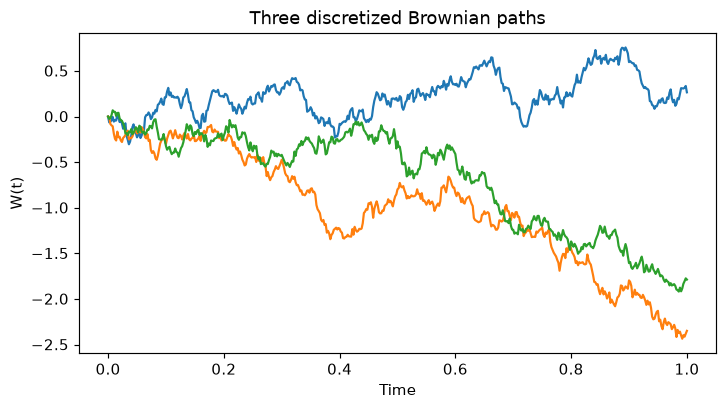

In [5]:
steps=500;dt=1/steps;times=np.linspace(0,1,steps+1)
paths=np.column_stack([np.zeros(3),np.cumsum(rng.normal(0,np.sqrt(dt),size=(3,steps)),axis=1)]).T
fig,ax=plt.subplots();ax.plot(times,paths)
ax.set(title="Three discretized Brownian paths",xlabel="Time",ylabel="W(t)");fig.tight_layout();plt.show()

## AI/ML application and interpretation

Markov models support reinforcement learning, sequence models, and MCMC; Poisson processes model event streams; martingale ideas support sequential inference; diffusion models motivate some generative processes. Check whether the chosen state, time scale, independence, and stationarity assumptions fit the application.

## Practice

1. Does the Markov property imply independent observations?
2. Can a stationary distribution exist without convergence from every start?
3. What distribution models a homogeneous Poisson interarrival time?
4. Is every martingale a Brownian motion?

## Solutions

1. No. The next state can depend strongly on the current state; the property removes additional history conditional on that state.
2. Yes. A periodic irreducible finite chain can have a unique stationary distribution but oscillate from a point start.
3. Exponential with the process rate; its mean is the reciprocal rate.
4. No. Random walks and compensated counts are other examples with different paths and state spaces.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](4_Time-Series-Statistics.ipynb).